# Stiffness 3 — steep fronts, discontinuous Galerkin

The same experiment as *Stiffness 3 — steep fronts*, on a DG grid.

A **step** into a column of pure transport. One front, and nothing else in the model: no binding, no particle, no second section. The sharpness of that front is set by the axial dispersion alone.

| | |
|---|---|
| bed length / diameter | 0.1 m / 0.01 m |
| superficial velocity | 4.2·10⁻⁴ m/s (150 cm/h) |
| bed porosity | 0.37 |
| feed | 1 mol/m³ from $t = 0$, never switched off |
| discretization | DG of degree $p$ on $N/(p+1)$ elements, or finite volumes with WENO |

Dispersion broadens a front as it travels, so after crossing the column its width is about

$$w \;\approx\; \sqrt{2 D \, L/u},$$

which is the only thing the dispersion knob changes.

**The third knob is what this notebook adds.** The FV study had two: how sharp the front is, and how many cells there are. DG splits the second one in half. A fixed number of nodes can be arranged as many low order elements or few high order ones — P1 on 128 elements, P3 on 64, P15 on 16 all carry 256 unknowns and solve the same equation — so *how many* degrees of freedom and *how they are arranged* become separate questions.

Degree 0 on the slider selects finite volumes with WENO, so the baseline of the FV notebook sits on the same axis and can be read directly against the DG variants.

In [ ]:
# This notebook lives one folder below the workshop root, while `utility`
# and everything under `data/` are addressed relative to that root.
# Step up into it before importing anything.
import os
import sys

root = os.path.abspath(os.curdir)
while not os.path.isdir(os.path.join(root, 'utility')):
    root, previous = os.path.dirname(root), root
    if root == previous:
        raise RuntimeError('no folder containing utility/ above this notebook')

os.chdir(root)
if root not in sys.path:
    sys.path.insert(0, root)

,process,rate / s^-1,set by,time scale / s
0,"convection, one grid node",6.538378,discretization,0.152943
1,"axial dispersion, one grid node",3.317760,discretization,0.301408
2,"convection, whole column",0.011351,physics,88.095238
3,"axial dispersion, whole column",0.000010,physics,100000.000000


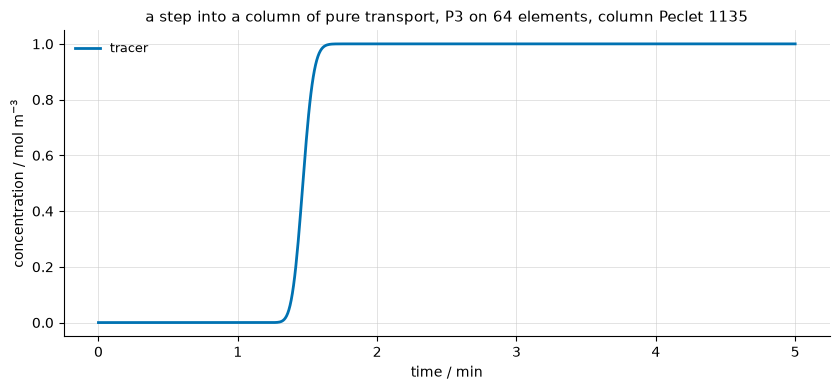

In [1]:
import utility.steep_front_dg_explorer as explorer

explorer.show_setting()

## What to watch

Three knobs now, and the useful comparisons hold two of them still.

| column | what it measures |
|---|---|
| `front / node` | front width over the **average** spacing of the unknowns, $L/N$. The fair resolution measure at a fixed system size: it is identical for every degree at the same node count. |
| `front / element` | front width over the **element** size. This is the quantity that has no counterpart in the FV study, where a cell and a degree of freedom are the same thing. |
| `oscillation / %` | how far the outlet signal leaves the interval $[0, \text{feed}]$ it should never leave. |

That last column is the one that does not exist in the FV notebook, and the reason it is here is this:

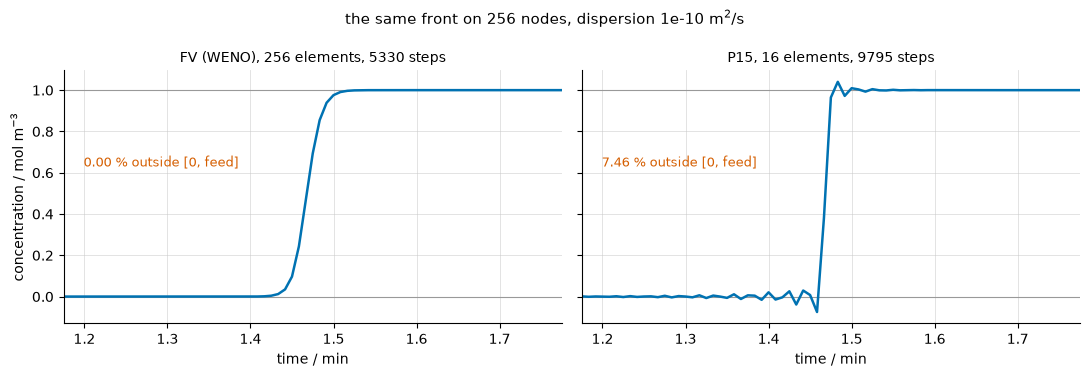

In [2]:
explorer.compare_fronts();

Both grids carry 256 unknowns and integrate the same equation. WENO is **monotone**, so when the front is sharper than the grid can hold it gets smeared and nothing else happens — which is exactly why the FV notebook could say "no oscillations to blame". DG has no limiter switched on here, so it keeps the front sharp and pays for it by ringing around it.

Note that DG is not simply doing worse. It puts the front in very nearly the right place with a nearly vertical rise, where WENO has spread it over a tenth of a minute. It trades smearing for ringing.

**The question this notebook asks:** does the cost still follow resolution the way it did for finite volumes, and if so, which resolution — the nodes or the elements?

In [ ]:
from ipywidgets import interact

show_front = explorer.make_explorer()

interact(show_front, **show_front.sliders);

interactive(children=(SelectionSlider(continuous_update=False, description='col dispersion', index=2, options=…

## Accuracy or stability?

The step counts above are large, and a large step count has two possible causes that it cannot by itself distinguish. Either the integrator is keeping the **local error** inside the tolerance you asked for, or it is staying inside the **stability region** and has no choice in the matter. Only the second one is stiffness.

The test is to ask for less accuracy. If accuracy is what binds, the steps come back in proportion. If stability is, there is a floor no tolerance can buy past, because a larger step there would not be inaccurate — it would be divergent.

Run on the worst case in this notebook: 256 nodes, dispersion 10⁻¹⁰, where the P15 front is a third of a node wide and ringing at 7.5 %.

In [ ]:
explorer.tolerance_sweep()

## What happened

**The cost law carries over unchanged, and the element size has nothing to do with it.**

At 256 nodes, taking the dispersion from 10⁻⁵ to 10⁻¹¹:

| grid | elements | steps at 10⁻⁵ | at 10⁻¹¹ | cost | worst oscillation |
|---|---|---|---|---|---|
| FV (WENO) | 256 | 652 | 5336 | ×8.2 | 0.00 % |
| P3 | 64 | 712 | 6254 | ×8.8 | 8.89 % |
| P15 | 16 | 752 | 10029 | ×13.3 | 9.17 % |

**It saturates at the same place on every grid — one front width per node.** This is the FV result repeated, and the threshold does not move when the degrees of freedom are rearranged:

| dispersion | front / node | FV | P3 | P15 | P3 osc. | P15 osc. |
|---|---|---|---|---|---|---|
| 10⁻⁷ | 10.75 | 1833 | 1920 | 1975 | 0 % | 0 % |
| 10⁻⁸ | 3.40 | 4213 | 4423 | 4757 | 0 % | 0 % |
| 10⁻⁹ | 1.07 | 5064 | 6100 | 9014 | 4.5 % | 1.0 % |
| 10⁻¹⁰ | 0.34 | 5330 | 6240 | 9795 | 8.4 % | 7.5 % |
| 10⁻¹¹ | 0.11 | 5336 | 6254 | 10029 | 8.9 % | 9.2 % |

Every column climbs until `front / node` passes one and then stops: the last two decades of dispersion cost FV 0.1 %, P3 0.2 % and P15 2.4 %. The oscillations switch on at the same line.

**The element size is not the criterion, and we expected it to be.** The natural guess is that an element is DG's version of a cell, so a front narrower than one element cannot be represented. The data says otherwise. At 10⁻⁸ the P15 front is **0.21 elements** wide and the solution is perfectly monotone, while at 10⁻⁹ the P3 front is **0.27 elements** wide and already ringing at 4.5 %. Sorted by `front / element` the two disagree; sorted by `front / node` they agree exactly. The polynomial inside an element really does resolve down to its own node spacing — which is what high order is for.

**What the degree does cost is the step itself.** At 512 nodes and 10⁻¹¹, finite volumes take 8803 steps in 2.12 s and P15 takes 16891 in 14.59 s — about **3.6× more per step** for the same number of unknowns, because a DG element contributes a dense block to the Jacobian where a finite volume cell contributes a few bands. That is the same "cost per step, not number of steps" bill the rest of the chapter keeps running into.

**And none of it is stiffness.** The tolerance sweep settles it: four decades of `RELTOL` return the steps in the same proportion on both grids — ×0.20 for finite volumes, ×0.25 for P15 — with no floor anywhere. A stability-limited run cannot do that. The BDF order agrees, sitting between 4.92 and 5.00 across all 140 combinations of the three sliders, at degree 15, with a front one tenth of a node wide and the solution visibly oscillating.

That is worth dwelling on, because the degree is the one knob in this chapter that provably *does* make the system stiffer. Clustering the nodes inside an element multiplies the convective spectrum by fourteen at 256 nodes: $u/\Delta z$ goes from 2.9 to 40.9 s⁻¹ between FV and P15. Where the front is resolved, that fourteenfold increase costs **8 %**. The spectrum grew; the bill did not.

<details>
<summary><b>Click to learn more: where the extra DG steps actually are</b></summary>

Not at breakthrough, and not where the ringing is visible. Counting the steps IDAS took in windows of simulated time, at 256 nodes and dispersion 10⁻¹⁰, with the front reaching the outlet at 88.5 s:

| window / s | FV | P15 | excess |
|---|---|---|---|
| 0 – 40 | 2878 | 5641 | 2763 |
| 40 – 80 | 1928 | 3116 | 1188 |
| 80 – 110 | 519 | 1032 | 513 |
| 110 – 300 | 5 | 6 | 1 |

**62 % of the excess is spent before $t = 40$ s, while the outlet is still flat at zero.** The front is still inside the bed then, and that is the point: the cost is not in the signal you look at, it is in carrying a sharp feature across the column for 88 s. Averaged over the steps actually taken, P15 runs at $h = 7.1\cdot10^{-3}$ s against finite volumes' $1.5\cdot10^{-2}$ s — a factor 2.1, which is the whole of the 1.8× step count.

Why a smaller step for the same equation? Because the front really is sharper. WENO has smeared it, DG has not, and a sharper feature advecting past a node has larger time derivatives there — which is exactly what BDF sizes its step from. The extra steps are what the sharper spatial answer costs in time.

**One thing this measurement cannot separate.** The ringing travels with the front, so during those first 40 s the interior is both sharper *and* oscillating, and an outlet trace cannot say which is doing the work. The dispersion sweep argues they are the same event: while the front is resolved DG costs 8 – 13 % more than FV and does not ring, and past front/node ≈ 1 it costs 78 – 84 % more and rings. Ringing is simply the form underresolution takes when no limiter is switched on.

If you need the sharp front without it, that is what the oscillation suppression options are for; this notebook leaves them off so the mechanism stays visible.

</details>

> **Take-away.** Everything the FV notebook concluded about steep fronts holds for DG, with the same threshold measured in **nodes, not elements** — a high order element resolves a front much narrower than itself. What changes is the failure mode past that threshold: finite volumes with WENO smear and go quiet, DG rings. Count the degrees of freedom across your sharpest feature, not the elements, and if the answer is below about one, expect either a smeared front or an oscillating one depending on which scheme you picked. And none of this is stiffness: the degree multiplies the spectrum by fourteen and that part is free, while everything you actually pay for is the error controller resolving a sharper solution in time.